# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [41]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
df = pd.read_csv('/content/listings.csv.gz').drop(columns=['calendar_updated', 'license', 'scrape_id', 'neighborhood_overview'])
df['review_scores_communication'] = df['review_scores_communication'].fillna(df['review_scores_communication'].median())
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)
df['price'] = pd.to_numeric(df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')

In [42]:
df.shape

(43751, 86)

## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

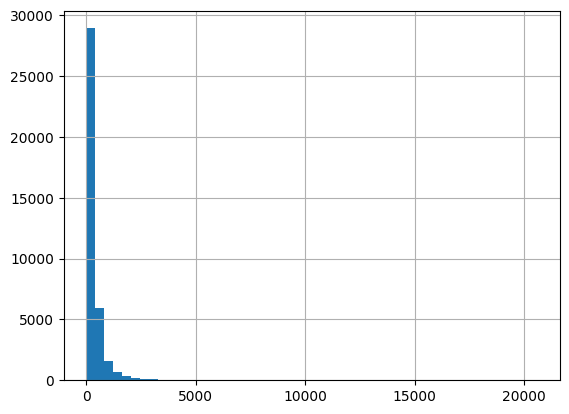

<Axes: >

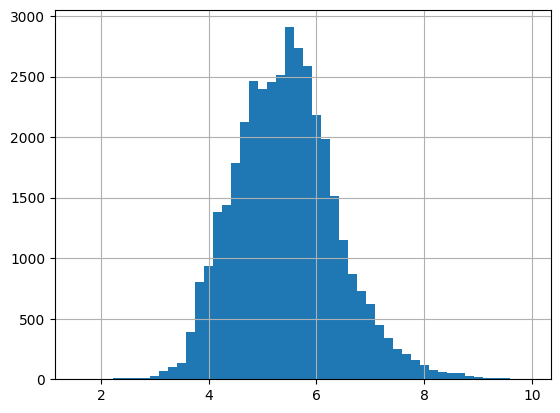

In [43]:
df['price'].hist(bins=50)
plt.show()
df['price_log'] = np.log1p(df['price'])
df['price_log'].hist(bins=50)

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined the price column.

2. I applied a log transformation (log1p). Price is heavily right-skewed, with a few listings costing thousands of dollars while most cost a few hundred. Log compresses the long tail and handles zeros safely.

3. The original histogram was crushed against the left edge, so patterns were hard to see. After the log transform, the distribution looks much closer to a bell curve, which makes it easier to summarize, show to stakeholders, and use in models.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [44]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale
df['availability_scaled'] = MinMaxScaler().fit_transform(df[['availability_365']])

# Z-score scale
df['price_zscore'] = StandardScaler().fit_transform(df[['price']])



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled availability_365 with Min-Max scaling (0 to 1) and price with Z-score standardization (mean 0, standard deviation 1).

2. Scaled values help when comparing or combining columns with very different ranges, like price (up to $20,000) and availability (0 to 365). They matter most in models like KNN or regression, where larger numbers can otherwise dominate.

3. Data scientists building pricing or recommendation models would benefit most, since the model can weigh each column fairly. Analysts also benefit, because a Z-score shows quickly how far a listing’s price is from the average.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [45]:
df['review_level'] = pd.cut(df['number_of_reviews'], bins=[-1, 10, 50, np.inf], labels=['Low', 'Medium', 'High'])
df['review_level'].value_counts()

,count
review_level,
Low,24456
High,9674
Medium,9621


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped number_of_reviews into 3 categories: Low (0-10), Medium (11-50), and High (more than 50).

2. A grouped view is easier to read and present than raw counts, and it reduces the effect of extreme values. Here, 24,456 listings are Low, 9,621 are Medium, and 9,674 are High.

3. The marketing team could use it to segment listings, for example by promoting Low-review listings or highlighting High-review ones. Hosts could also see where their listing stands.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [46]:
df['price_per_min_night'] = df['price'] / df['minimum_nights']
df['long_term_stay'] = (df['minimum_nights'] >= 30).astype(int)
df[['price_per_min_night', 'long_term_stay']].head()

,price_per_min_night,long_term_stay
0,2.240667,1
1,213.560000,0
2,3.321000,1
3,3.173667,1
4,113.000000,0


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created price_per_min_night (price ÷ minimum nights) and long_term_stay (1 if the minimum stay is 30 nights or more). They show the true cost of a minimum booking and separate long-term rentals from short stays.

2. Hosts, pricing analysts, and city planners tracking long-term rentals would use them.

3. A host can see whether their minimum stay makes the listing expensive compared with similar ones. The platform or city can spot listings that behave more like long-term rentals than short-term stays.




## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [47]:
df = pd.get_dummies(df, columns=['room_type'], prefix='room', dtype=int)
df.filter(like='room_').head()

,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,0,0,1,0
1,0,0,1,0
2,1,0,0,0
3,0,0,1,0
4,0,0,1,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded room_type, because models can’t use text categories directly.
2. I used one-hot encoding, since the four room types (Entire home/apt, Private room, Hotel room, Shared room) have no natural order. It added 4 columns and dropped the original.
3. A pricing model can learn the effect of each room type on price separately. Dashboards and reports can also filter or compare by room type more easily.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [48]:
df.to_csv('cleaned_airbnb_data_7.csv', index=False)

In [49]:
df = df.drop(columns=[c for c in df.columns if 'url' in c or c in ['name', 'description', 'host_about']])

In [50]:
df.shape

(43751, 86)

## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. Log-transforming price felt most important, because it turned a hard-to-read distribution into something usable.

2. The long_term_stay and price_per_min_night features would be most useful to hosts and city planners, since they turn raw columns into business signals.
3. I would build a dashboard comparing price per night across neighborhoods and room types, then use this cleaned data for the regression model in Assignment 11.
4. This relates to my goal of practicing data oraginzaing and uncovering, because I cleaned, transformed, and encoded a real dataset so it’s ready for modeling and reporting.


## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [52]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"

[NbConvertApp] Converting notebook assignment_07_data_transformation.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 367749 bytes to assignment_07_data_transformation.html
